# eQTL / dsQTL benchmark 6 — who finds *which* variant?

Every other panel in this project reduces a benchmark to one number per model. That number
cannot distinguish two very different worlds:

* **Redundancy.** Every model ranks the same variants highest. The AP differences are then a
  matter of ordering the same short list, and an ensemble buys nothing.
* **Complementarity.** The models recover largely disjoint variants. Similar AP then hides the
  fact that they are reading different signal, and the union is worth much more than any arm.

This notebook answers that with UpSet plots over both benchmarks.

---

## Do you have to pick a threshold? Yes — but pick a *rank*, not a value.

UpSet needs sets, and model outputs are continuous, so binarising is unavoidable. Three rules
make it defensible:

**1. Never threshold on the score value.** The arms are not on a common scale. AlphaGenome
predicts in its own units, Enformer is binned at 128 bp against Borzoi's 32 bp, and ChromBPNet's
IPS is not even a fold-change. A single numeric cutoff would compare nothing.

**2. Give every model the same budget: top-K by its own rank.** Each arm calls exactly `K`
variants, so no arm can win an intersection merely by being liberal, and every set in the plot is
the same size by construction. This is the convention Panel H of `IGVF_meeting_figures` already uses
(each arm scored at its own p95).

**3. Set `K` = the number of true positives.** "Each model names as many variants as there
actually are." At that budget precision equals recall, so the diagonal of the UpSet is directly
the model's hit count. `K` is swept later so no conclusion rests on the specific value.

## And the population you run UpSet over is the bigger choice

* **Over recovered true positives** — *do the models find different real variants?* This is the
  question worth asking, and the only version whose answer implies anything about ensembling.
* **Over all called variants** — *do the models behave alike?* Weaker: two models can overlap
  heavily here just by both firing on the same GC-rich or repeat-adjacent junk.

Both are below, plus a **Spearman rank-correlation heatmap** that needs no cutoff at all — if the
threshold-free and threshold-based views agree, the choice of `K` was not doing the work.

**Conventions carried over from `IGVF_meeting_figures`:** common support only (an arm is compared only
where every arm could see the variant), `|logFC|` as the score, family colours unchanged.


## 0. Setup

In [1]:
# ============================================================================
# eQTL / dsQTL overlap analysis - setup, palette, loaders.
# Runs top-to-bottom on a cold kernel; nothing is read from another notebook.
# ============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import spearmanr

FIGDIR = '/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/eqtl/upset_figs'
os.makedirs(FIGDIR, exist_ok=True)

# --- palette: identical to IGVF_meeting_figures so the two notebooks agree ---------
C_OURS = '#2a78d6'   # cis-Mamba (this work)
C_ENF  = '#eb6834'   # Enformer family
C_BOR  = '#1baf7a'   # Borzoi family
C_AG   = '#4a3aa7'   # AlphaGenome
C_CBP  = '#b03060'   # ChromBPNet
C_REF  = '#6b7280'   # measurements / null / chance -- never a model

FAMILY = {'ours': C_OURS, 'enformer': C_ENF, 'borzoi': C_BOR,
          'alphagenome': C_AG, 'chrombpnet': C_CBP, 'reference': C_REF}

mpl.rcParams.update({
    'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12.5,
    'xtick.labelsize': 10.5, 'ytick.labelsize': 10.5, 'legend.fontsize': 10.5,
    'figure.dpi': 110, 'savefig.dpi': 300, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.linewidth': 0.9,
    'axes.edgecolor': '#444444', 'text.color': '#222222',
    'axes.labelcolor': '#222222', 'xtick.color': '#444444',
    'ytick.color': '#444444', 'figure.facecolor': 'white',
})
INK, INK2 = '#222222', '#555555'


def tidy(ax, grid='y'):
    ax.grid(axis=grid, ls='--', lw=0.55, color='#CCCCCC', zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis='x' if grid == 'y' else 'y', length=0)
    return ax

In [2]:
# ============================================================================
# LOADERS - ported verbatim from IGVF_meeting_figures section 14 so this notebook is
# self-contained.  Same gating, same window matching, same |logFC| score.
# ============================================================================
import pickle, zarr

QTL = '/data1/lesliec/sarthak/data/joint_playground/eQTL/EPCOTv2_LCLs/'
DSQ = '/data1/lesliec/sarthak/data/joint_playground/dsQTL'
CBP = '/data1/lesliec/sarthak/data/chrombpnet/dsqtls.yoruba.lcls.benchmarking.all.tsv'


def abs_logfc(win):
    """|log2 mean(ref) / mean(alt)| over the scoring window; 0 where unscored."""
    r, a = win[:, :, 0], win[:, :, 1]
    unscored = (r.sum(1) == 0) & (a.sum(1) == 0)
    out = np.zeros(len(r))
    v = ~unscored
    out[v] = np.log2(r[v].mean(1) / a[v].mean(1))
    return np.abs(out), ~unscored


def load_eqtl():
    N, CENTER_BP = 1331, 2048
    q = pd.read_csv(QTL + 'LCLs.txt', sep=' ', header=None)
    q.columns = ['label', 'qtl_idx', 'gene_idx', 'chrom', 'gene_start',
                 'gene_end', 'strand', 'qtl_loc', 'ref', 'alt', 'sign_target']
    labels = q['label'].to_numpy()
    genes = sorted(pickle.load(open(QTL + 'genes.pickle', 'rb')).keys())
    t = np.loadtxt(QTL + 'ensemblTSS.txt', dtype='str')
    tss = {t[i, 0]: int(t[i, 1]) for i in range(t.shape[0])}
    dist = np.array([abs(tss[genes[q.iloc[i]['gene_idx']]] - (q.iloc[i]['qtl_loc'] - 1))
                     for i in range(N)])

    ARMS = [
        ('cis-Mamba (1 cell type)',   'ours',        'nomlm_maskonly.npy',      128),
        ('cis-Mamba, no pretraining', 'ours',        'nopretrain.npy',          128),
        ('cis-Mamba (8 cell types)',  'ours',        'immune.npy',              128),
        ('Enformer (pretrained)',     'enformer',    'enformer_eqtl.npy',       128),
        ('Borzoi (pretrained)',       'borzoi',      'borzoi_eqtl.npy',          32),
        ('Borzoi LoRA (GM12878)',     'borzoi',      'borzoi_eqtl_lorav2.npy',   32),
        ('Borzoi full FT (GM12878)',  'borzoi',      'borzoi_eqtl_trunk.npy',    32),
        ('Borzoi from scratch (GM12878)', 'borzoi',  'borzoi_eqtl_scratch.npy',  32),
        ('AlphaGenome',               'alphagenome', 'alphagenome_eqtl.zarr',     1),
    ]
    S, SC = {}, {}
    for lab, fam, f, bp in ARMS:
        if f.endswith('.zarr'):
            full = np.asarray(zarr.open(QTL + f, mode='r')[:], dtype=np.float64)
        else:
            full = np.asarray(np.load(QTL + f, mmap_mode='r'), dtype=np.float64)
        assert full.shape[0] == N and full.shape[2] == 2, (lab, full.shape)
        nb_ = CENTER_BP // bp
        cs = full.shape[1] // 2 - nb_ // 2
        S[lab], SC[lab] = abs_logfc(full[:, cs:cs + nb_, :])
    common = np.logical_and.reduce([SC[l] for l, *_ in ARMS])
    return dict(arms=ARMS, labels=labels, dist=dist, S=S, SC=SC, common=common)


def chrombpnet_dsqtl(q, encid, score):
    """One (experiment, scorer) pair from the published ChromBPNet benchmark table."""
    t = pd.read_csv(CBP, sep='\t')
    k = t['var.chr'].astype(str) + ':' + t['var.pos_hg19'].astype(str)
    t = t.assign(_k=k).drop_duplicates('_k').set_index('_k')
    r = t.reindex(q['chrom_hg19'].astype(str) + ':' + q['pos_hg19'].astype(str))
    s = r[f'pred.chrombpnet.{encid}.varscore.{score}'].to_numpy(dtype=np.float64)
    ok = ~np.isnan(s)
    assert (r['var.allele1'].to_numpy()[ok] == q['allele1'].to_numpy()[ok]).all()
    assert (r['obs.label'].to_numpy()[ok] == q['label'].to_numpy()[ok]).all()
    return np.abs(np.nan_to_num(s)), ok


def load_dsqtl():
    q = pd.read_csv(f'{DSQ}/filtered_dsqtls.txt', sep='\t')
    labels = (q['label'].to_numpy() == 1).astype(int)
    ARMS = [
        ('cis-Mamba (GM12878 DNase logFC)', 'ours',      'nomlm_maskonly.npy'),
        ('Enformer (pretrained)',         'enformer',    'enformer_dsqtl.npy'),
        ('Enformer retrained (GM12878)',  'enformer',    'enformer_dsqtl_retrained-dsqtl.npy'),
        ('Borzoi (pretrained)',           'borzoi',      'borzoi_dsqtl_pretrained_1288.npy'),
        ('Borzoi LoRA (GM12878)',         'borzoi',      'borzoi_dsqtl_lorav2.npy'),
        ('Borzoi full FT (GM12878)',      'borzoi',      'borzoi_dsqtl_trunk.npy'),
        ('Borzoi from scratch (GM12878)', 'borzoi',      'borzoi_dsqtl_scratch.npy'),
        ('AlphaGenome',                   'alphagenome', 'alphagenome_dsqtl.zarr'),
        ('ChromBPNet (GM12878 DNase logFC)', 'chrombpnet', ('encsr000emt', 'logfc')),
        ('ChromBPNet (GM12878 DNase IPS)',   'chrombpnet', ('encsr000emt', 'ips')),
        ('ChromBPNet (GM12878 ATAC logFC)',  'chrombpnet', ('encsr637xsc', 'logfc')),
        ('ChromBPNet (GM12878 ATAC IPS)',    'chrombpnet', ('encsr637xsc', 'ips')),
    ]
    S, SC = {}, {}
    for lab, fam, f in ARMS:
        if isinstance(f, tuple):
            S[lab], SC[lab] = chrombpnet_dsqtl(q, *f)
            continue
        if f.endswith('zarr'):
            d = np.asarray(zarr.open(f'{DSQ}/{f}')[:, :, :], dtype=np.float64)
        elif 'borzoi' in f:
            a = np.load(f'{DSQ}/{f}', mmap_mode='r')
            m, h = 6144 // 2, 2048 // 32 // 2
            d = np.asarray(a[:, m - h:m + h, :], dtype=np.float64)
        else:
            d = np.asarray(np.load(f'{DSQ}/{f}'), dtype=np.float64)
            if 'enformer' in f:
                d = d[:, 440:456, :]
        S[lab], SC[lab] = abs_logfc(d)
    common = np.logical_and.reduce([SC[l] for l, *_ in ARMS])
    return dict(arms=ARMS, labels=labels, S=S, SC=SC, common=common)

In [3]:
# Loading the raw prediction arrays cold takes ~6 min; everything downstream only
# needs the collapsed (variants x arms) matrices, so cache those.  Delete the file
# to force a reload after any loader change.
CACHE = '/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/eqtl/.upset_cache.npz'

if os.path.exists(CACHE):
    _z = np.load(CACHE, allow_pickle=True)
    EQ = dict(name='eQTL',  labels=list(_z['eq_labels']), X=_z['eq_X'], y=_z['eq_y'],
              fam=dict(zip(_z['eq_labels'], _z['eq_fam'])))
    DQ = dict(name='dsQTL', labels=list(_z['dq_labels']), X=_z['dq_X'], y=_z['dq_y'],
              fam=dict(zip(_z['dq_labels'], _z['dq_fam'])))
    for B in (EQ, DQ):
        print(f"{B['name']:6s}  n={B['X'].shape[0]:6,d}  arms={B['X'].shape[1]:2d}  "
              f"positives={B['y'].sum():4d}  ({B['y'].mean():.1%})   [cached]")
else:
    E  = load_eqtl()
    DS = load_dsqtl()


    def bench(raw, name):
        """Collapse a loader's output to the common-support matrix the analysis uses."""
        m = raw['common']
        arms = [(l, f) for l, f, *_ in raw['arms']]
        X = np.column_stack([raw['S'][l][m] for l, _ in arms])   # variants x arms
        y = np.asarray(raw['labels'])[m].astype(int)
        fam = {l: f for l, f in arms}
        print(f'{name:6s}  n={X.shape[0]:6,d}  arms={X.shape[1]:2d}  '
              f'positives={y.sum():4d}  ({y.mean():.1%})')
        return dict(name=name, labels=[l for l, _ in arms], fam=fam, X=X, y=y)

    EQ = bench(E,  'eQTL')
    DQ = bench(DS, 'dsQTL')
    np.savez_compressed(
        CACHE,
        eq_labels=np.array(EQ['labels']), eq_fam=np.array([EQ['fam'][l] for l in EQ['labels']]),
        eq_X=EQ['X'], eq_y=EQ['y'],
        dq_labels=np.array(DQ['labels']), dq_fam=np.array([DQ['fam'][l] for l in DQ['labels']]),
        dq_X=DQ['X'], dq_y=DQ['y'])
    print(f'cached -> {CACHE}')

# Ties at the top-K boundary would make set membership arbitrary; check it is not an issue.
for B in (EQ, DQ):
    K = int(B['y'].sum())
    worst = max(int((B['X'][:, j] == np.sort(B['X'][:, j])[::-1][K - 1]).sum())
                for j in range(B['X'].shape[1]))
    print(f"{B['name']:6s}  K={K:4d}   largest tie-group at the K-th score: {worst}")

eQTL    n= 1,023  arms= 9  positives= 218  (21.3%)
dsQTL   n=17,506  arms=12  positives= 435  (2.5%)
cached -> /data1/lesliec/sarthak/caduceus/code_test/.upset_cache.npz
eQTL    K= 218   largest tie-group at the K-th score: 1
dsQTL   K= 435   largest tie-group at the K-th score: 1


---
## 1. The threshold-free view first

Spearman rank correlation between arms over the common support. No cutoff is involved, so
whatever this shows cannot be an artefact of `K`. If two arms are near-1 here, they are the same
detector and the UpSet will say so too.


eQTL: off-diagonal rho ranges 0.54 to 0.83


dsQTL: off-diagonal rho ranges 0.30 to 0.88


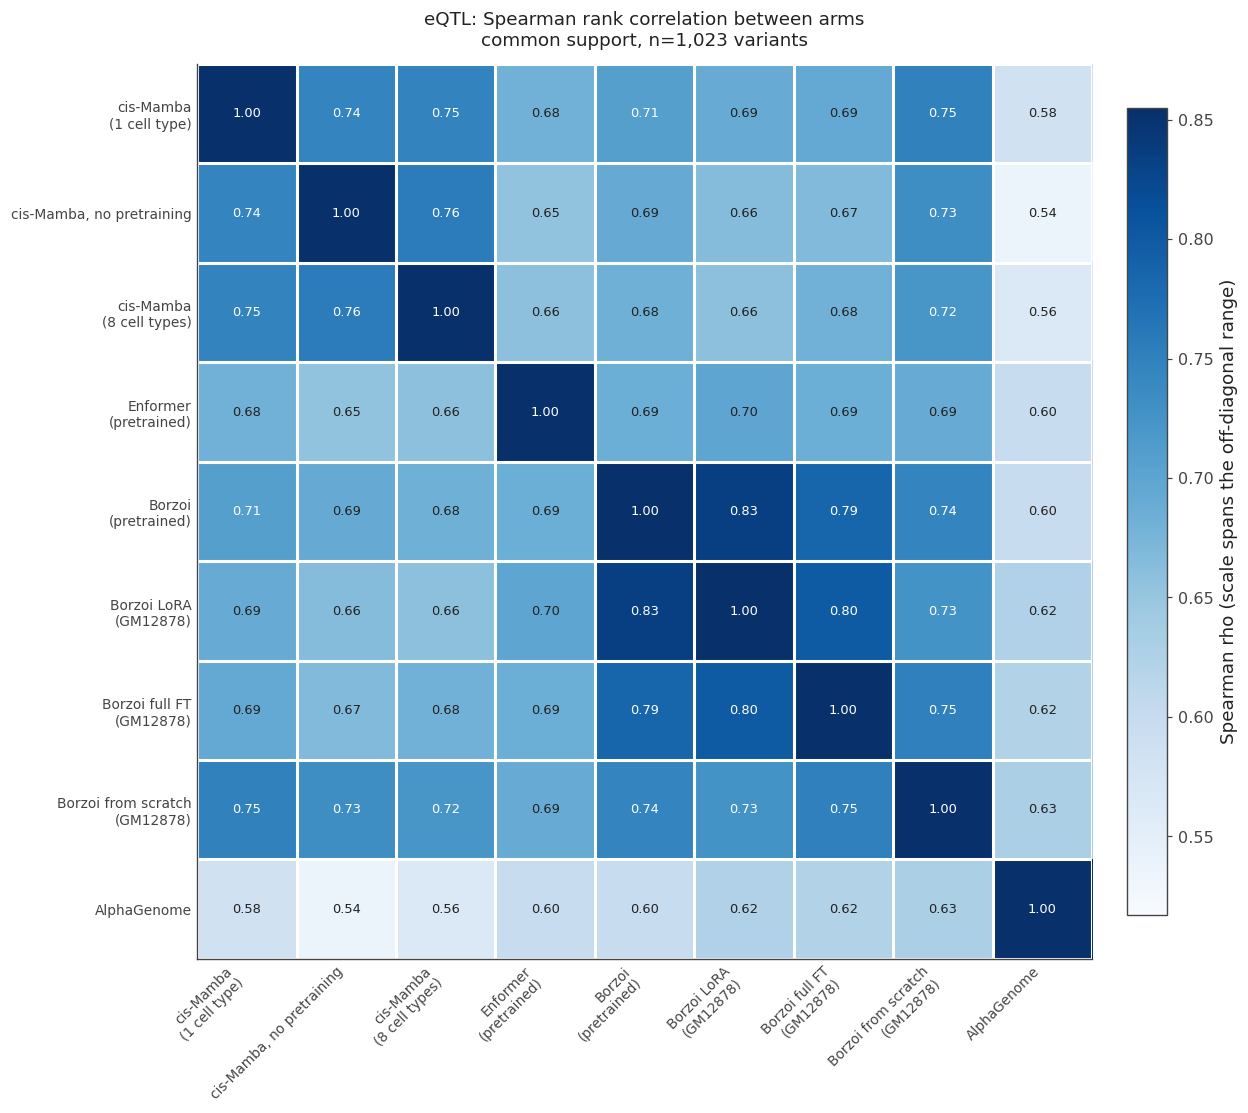

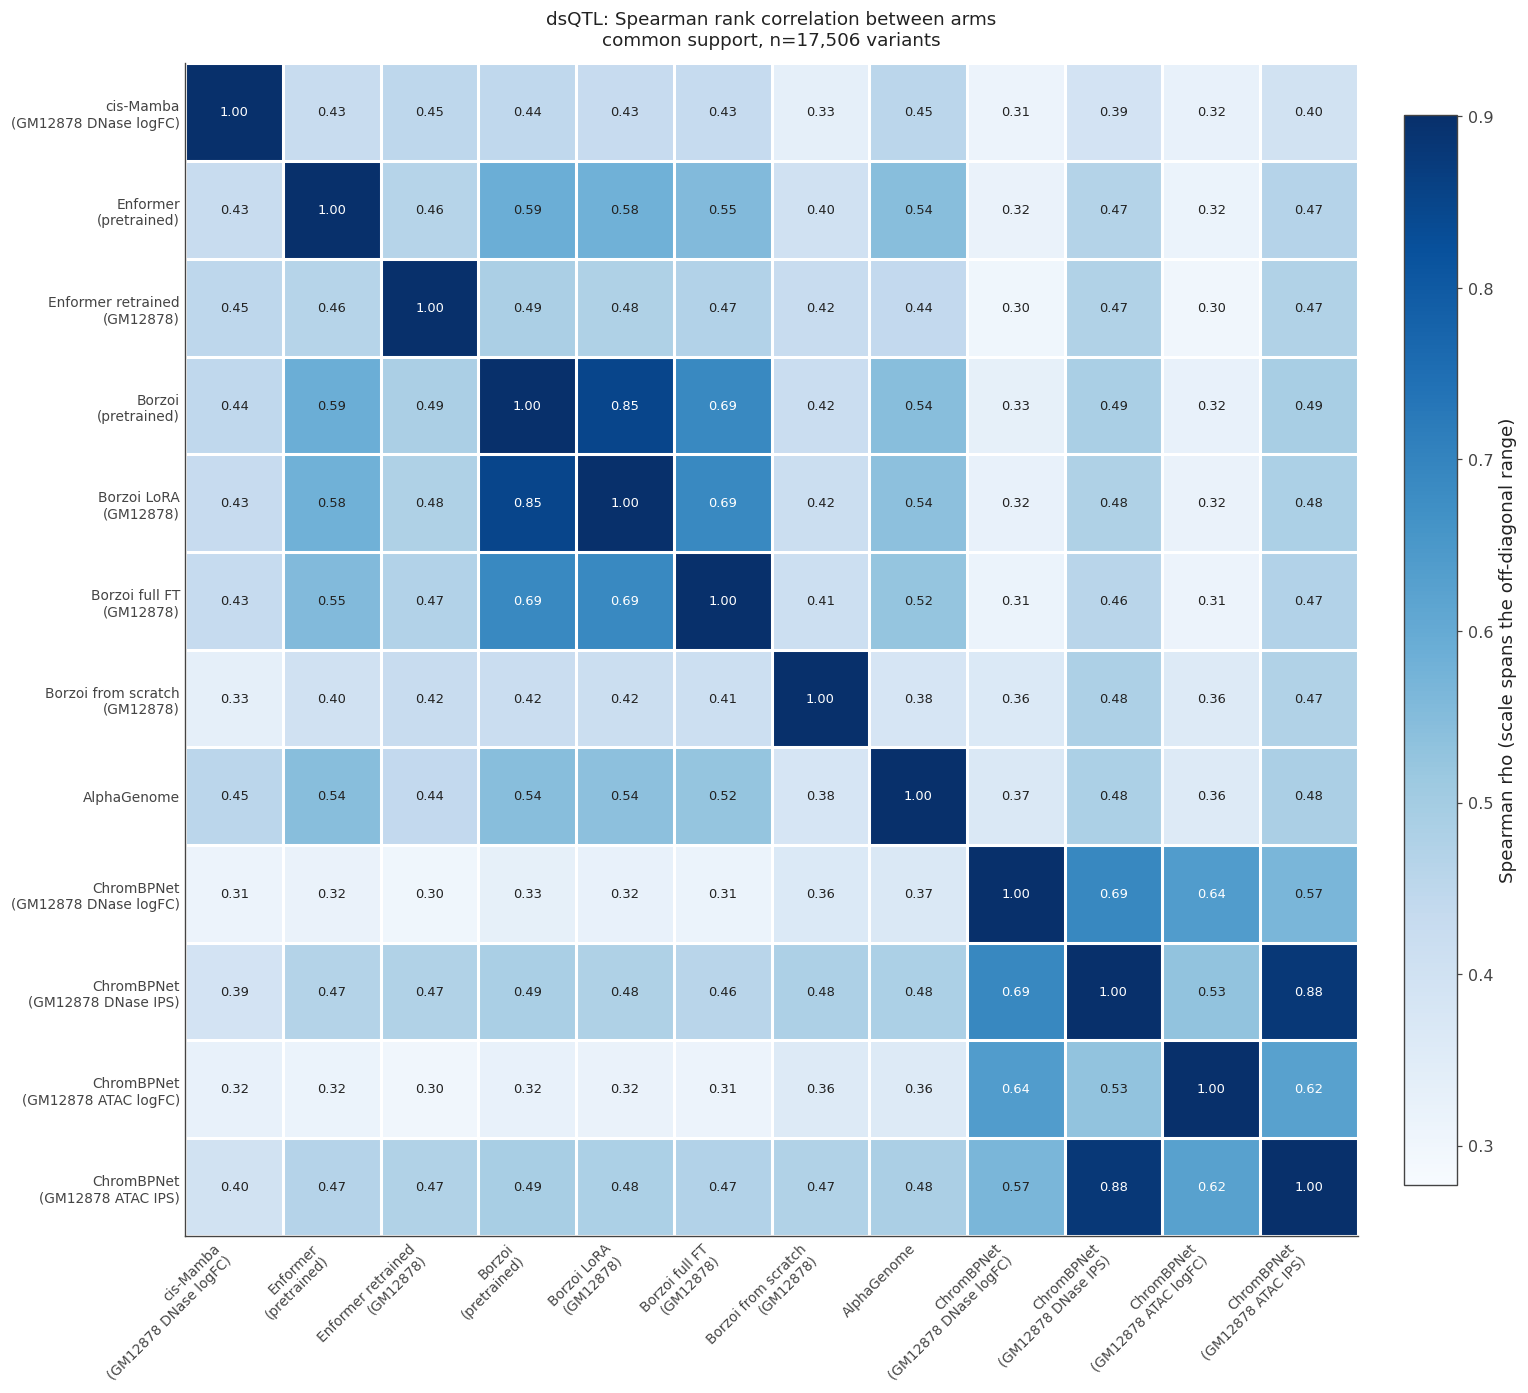

In [4]:
def corr_heatmap(B, path, short=None):
    """Spearman between every pair of arms. Sequential ramp - one hue, light to dark."""
    L = B['labels']
    R = spearmanr(B['X']).correlation
    R = np.atleast_2d(R)
    off = R[~np.eye(len(L), dtype=bool)]
    lo = float(np.nanmin(off))
    # One hue, light->dark; diverging only if the data actually crosses 0.  The ramp is
    # stretched over the OFF-DIAGONAL range -- anchoring at 0..1 would spend most of the
    # scale on values that never occur and flatten every real difference to one blue.
    if lo < 0:
        cmap, vmin, vmax = 'RdBu_r', -1.0, 1.0
        print(f'note: negative correlation present (min {lo:.2f}) -> diverging scale')
    else:
        cmap, vmin, vmax = 'Blues', max(0.0, lo - 0.02), float(np.nanmax(off)) + 0.02
        print(f'{B["name"]}: off-diagonal rho ranges {lo:.2f} to {np.nanmax(off):.2f}')

    names = short or [s.replace(' (', '\n(') for s in L]
    fig, ax = plt.subplots(figsize=(1.0 * len(L) + 3.2, 0.85 * len(L) + 2.6))
    im = ax.imshow(R, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(L))); ax.set_xticklabels(names, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(L))); ax.set_yticklabels(names, fontsize=9)
    for i in range(len(L)):
        for j in range(len(L)):
            v = R[i, j]
            # value on every cell: the matrix is small and the number is the point
            # ink flips on the ramp midpoint, not an absolute value, so labels stay legible
            mid = vmin + 0.55 * (vmax - vmin)
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8.5,
                    color='white' if v > mid else INK)
    ax.set_title(f"{B['name']}: Spearman rank correlation between arms\n"
                 f"common support, n={B['X'].shape[0]:,} variants", fontsize=12, pad=12)
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.03).set_label('Spearman rho (scale spans the off-diagonal range)')
    ax.set_xticks(np.arange(len(L) + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(L) + 1) - 0.5, minor=True)
    ax.grid(which='minor', color='white', lw=2)
    ax.tick_params(which='minor', length=0); ax.tick_params(length=0)
    fig.tight_layout(); fig.savefig(path, bbox_inches='tight')
    return R


R_EQ = corr_heatmap(EQ, f'{FIGDIR}/upset_corr_eqtl.png')
R_DQ = corr_heatmap(DQ, f'{FIGDIR}/upset_corr_dsqtl.png')
plt.show()

---
## 2. Building the sets

`top_k_sets` gives every arm the same budget `K` and returns a boolean membership matrix. Two
populations are derived from it:

* `hits` — membership restricted to **true positives** (the primary view)
* `calls` — membership over **all** variants (the secondary, behavioural view)


In [5]:
def top_k_sets(B, K, arms=None):
    """Boolean (variants x arms) membership: each arm calls exactly its own top K."""
    idx = [B['labels'].index(a) for a in (arms or B['labels'])]
    M = np.zeros((B['X'].shape[0], len(idx)), bool)
    for c, j in enumerate(idx):
        order = np.argsort(-B['X'][:, j], kind='stable')[:K]
        M[order, c] = True
    return M


def intersections(M, names, max_rows=20, min_size=1):
    """Exact-membership groups, largest first. Rows are disjoint and sum to the union."""
    keys = {}
    for i, row in enumerate(M):
        if not row.any():
            continue                      # found by no arm -- not an UpSet row
        keys.setdefault(row.tobytes(), []).append(i)
    rows = [(np.frombuffer(k, bool), len(v)) for k, v in keys.items()]
    rows = [r for r in rows if r[1] >= min_size]
    rows.sort(key=lambda r: (-r[1], r[0].sum()))
    return rows[:max_rows], rows

In [6]:
def upset(M, names, fam, title, subtitle, path, max_rows=20, figw=None):
    """Hand-rolled UpSet: intersection bars on top, membership matrix below,
    per-arm set sizes on the left.  No upsetplot dependency."""
    rows, all_rows = intersections(M, names, max_rows=max_rows)
    sizes = [n for _, n in rows]
    n_arms, n_int = len(names), len(rows)
    shown, total = sum(sizes), sum(n for _, n in all_rows)

    # The arm names live between the set-size bars and the matrix, so the gap between
    # those two columns has to be wide enough to hold the longest one.
    namew = 0.085 * max(len(n) for n in names) + 0.4          # inches
    setw = 1.5
    matw = 0.42 * n_int + 0.6
    figw = figw or (setw + namew + matw + 0.8)
    fig = plt.figure(figsize=(figw, 0.42 * n_arms + 4.6))
    gs = GridSpec(2, 2, width_ratios=[setw, matw],
                  height_ratios=[2.5, 0.42 * n_arms],
                  hspace=0.06, wspace=2 * namew / (setw + matw), figure=fig)
    ax_bar = fig.add_subplot(gs[0, 1])
    ax_mat = fig.add_subplot(gs[1, 1], sharex=ax_bar)
    # NOT sharey: set_yticks on a shared axis clears the shared locator and would wipe
    # the arm names off ax_mat.  The two are aligned by giving them identical ylim.
    ax_set = fig.add_subplot(gs[1, 0])
    fig.add_subplot(gs[0, 0]).axis('off')

    x = np.arange(n_int)
    # An intersection of exactly one arm is that arm's colour; shared ones are neutral,
    # so "only this model" reads off the chart instantly.
    bar_c = [FAMILY[fam[names[np.flatnonzero(m)[0]]]] if m.sum() == 1 else '#9aa1ab'
             for m, _ in rows]
    ax_bar.bar(x, sizes, width=0.62, color=bar_c, zorder=3)
    for xi, v in zip(x, sizes):
        ax_bar.text(xi, v + max(sizes) * 0.015, str(v), ha='center', va='bottom',
                    fontsize=8.5, color=INK2)
    ax_bar.set_ylabel('variants in\nthis intersection')
    ax_bar.set_ylim(0, max(sizes) * 1.16)
    tidy(ax_bar, 'y'); ax_bar.tick_params(labelbottom=False)
    ax_bar.set_title(f'{title}\n{subtitle}', fontsize=12, pad=12)

    # membership matrix
    y = np.arange(n_arms)
    for yi in y:
        ax_mat.axhspan(yi - 0.5, yi + 0.5, color='#f2f3f5' if yi % 2 == 0 else 'white',
                       zorder=0, lw=0)
    ax_mat.scatter(np.repeat(x, n_arms), np.tile(y, n_int),
                   s=42, color='#d6d9de', zorder=2)
    for xi, (m, _) in enumerate(rows):
        on = np.flatnonzero(m)
        col = FAMILY[fam[names[on[0]]]] if len(on) == 1 else '#3f4653'
        if len(on) > 1:
            ax_mat.plot([xi, xi], [on.min(), on.max()], lw=2.0, color=col, zorder=3)
        ax_mat.scatter([xi] * len(on), on, s=42, color=col, zorder=4)
    ax_mat.set_yticks(y); ax_mat.set_yticklabels(names, fontsize=9.5)
    ax_mat.set_ylim(n_arms - 0.5, -0.5)
    ax_mat.set_xlim(-0.7, n_int - 0.3)
    ax_mat.set_xticks([]); ax_mat.tick_params(length=0)
    for sp in ax_mat.spines.values():
        sp.set_visible(False)

    # per-arm set sizes
    ssz = M.sum(0)
    ax_set.barh(y, ssz, height=0.6, color=[FAMILY[fam[n]] for n in names], zorder=3)
    ax_set.set_ylim(n_arms - 0.5, -0.5)          # matches ax_mat; see the sharey note above
    ax_set.set_xlim(max(ssz) * 1.06, 0)          # inverted via the limits, not invert_xaxis()
    for yi, v in enumerate(ssz):
        # x is inverted, so ha='left' puts the text INSIDE the bar and never clips
        ax_set.text(v, yi, f'{v}  ', va='center', ha='left', fontsize=8.5, color='white')
    ax_set.set_xlabel('arm total')
    ax_set.set_yticks(y); ax_set.tick_params(axis='y', length=0, labelleft=False)
    tidy(ax_set, 'x')
    for sp in ('left', 'right', 'top'):
        ax_set.spines[sp].set_visible(False)

    fig.text(0.5, -0.03,
             f'{n_int} largest of {len(all_rows)} observed intersections  |  '
             f'{shown:,} of {total:,} variants shown  |  '
             f'grey bar = found by >1 arm, coloured bar = found by that arm alone',
             ha='center', fontsize=9, color=INK2)
    fig.savefig(path, bbox_inches='tight')
    return rows, all_rows

---
## 3. eQTL — which *true* eQTLs does each arm recover?

`K` = 218, the number of positives on common support. Restricted to positives, so a bar here is
real signal recovered, not shared behaviour.

`ARMS_EQ` is the readable subset — nine arms give 2^9 possible intersections and an unreadable
plot. The full-arm version follows.


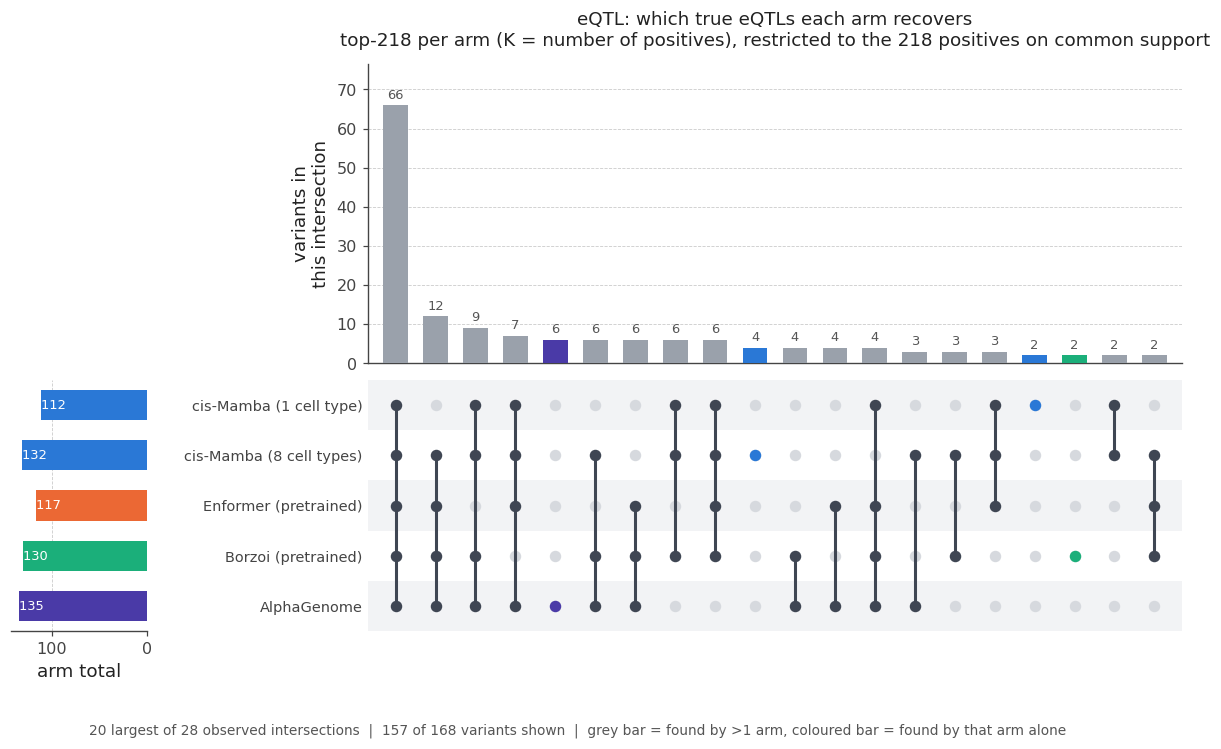

recovered by at least one arm : 168 / 218
missed by every arm           : 50


In [7]:
ARMS_EQ = ['cis-Mamba (1 cell type)', 'cis-Mamba (8 cell types)',
           'Enformer (pretrained)', 'Borzoi (pretrained)', 'AlphaGenome']

K_EQ = int(EQ['y'].sum())
pos = EQ['y'] == 1

M = top_k_sets(EQ, K_EQ, ARMS_EQ)[pos]
rows_eq, all_eq = upset(
    M, ARMS_EQ, EQ['fam'],
    'eQTL: which true eQTLs each arm recovers',
    f'top-{K_EQ} per arm (K = number of positives), restricted to the {pos.sum()} positives '
    f'on common support',
    f'{FIGDIR}/upset_eqtl_hits.png')
plt.show()

print(f'recovered by at least one arm : {sum(n for _, n in all_eq)} / {pos.sum()}')
print(f'missed by every arm           : {pos.sum() - sum(n for _, n in all_eq)}')

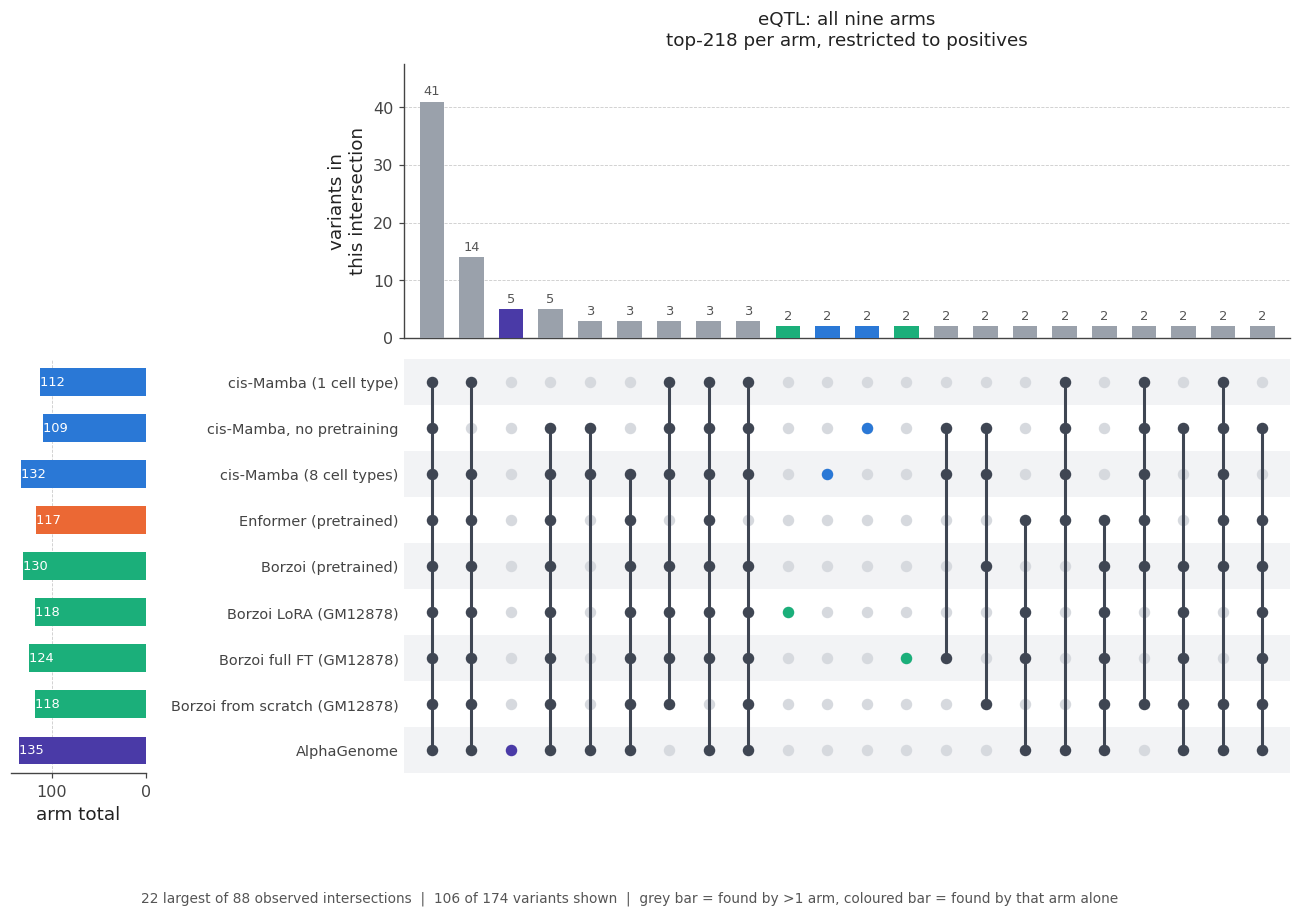

In [8]:
# All nine arms, top 22 intersections.
K_EQ = int(EQ['y'].sum())
M_all = top_k_sets(EQ, K_EQ)[EQ['y'] == 1]
rows, all_rows = upset(
    M_all, EQ['labels'], EQ['fam'],
    'eQTL: all nine arms',
    f'top-{K_EQ} per arm, restricted to positives',
    f'{FIGDIR}/upset_eqtl_hits_allarms.png', max_rows=22)
plt.show()

---
## 4. dsQTL — the same, on chromatin QTLs

`K` = 435. The four ChromBPNet arms are collapsed to the single best (ATAC + IPS) for the
readable version — four scorers of one model would otherwise dominate the matrix with
ChromBPNet-internal agreement.


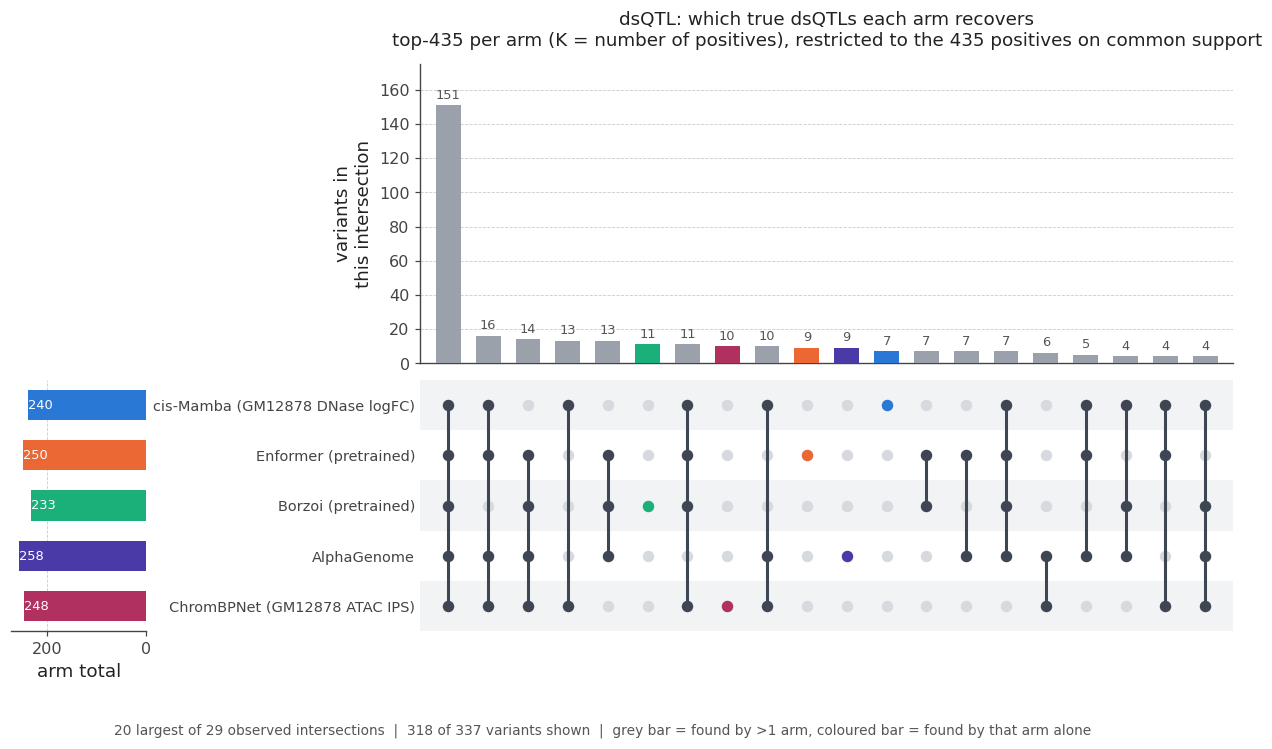

recovered by at least one arm : 337 / 435
missed by every arm           : 98


In [9]:
ARMS_DQ = ['cis-Mamba (GM12878 DNase logFC)', 'Enformer (pretrained)',
           'Borzoi (pretrained)', 'AlphaGenome', 'ChromBPNet (GM12878 ATAC IPS)']

K_DQ = int(DQ['y'].sum())
posd = DQ['y'] == 1

Md = top_k_sets(DQ, K_DQ, ARMS_DQ)[posd]
rows_dq, all_dq = upset(
    Md, ARMS_DQ, DQ['fam'],
    'dsQTL: which true dsQTLs each arm recovers',
    f'top-{K_DQ} per arm (K = number of positives), restricted to the {posd.sum()} positives '
    f'on common support',
    f'{FIGDIR}/upset_dsqtl_hits.png')
plt.show()

print(f'recovered by at least one arm : {sum(n for _, n in all_dq)} / {posd.sum()}')
print(f'missed by every arm           : {posd.sum() - sum(n for _, n in all_dq)}')

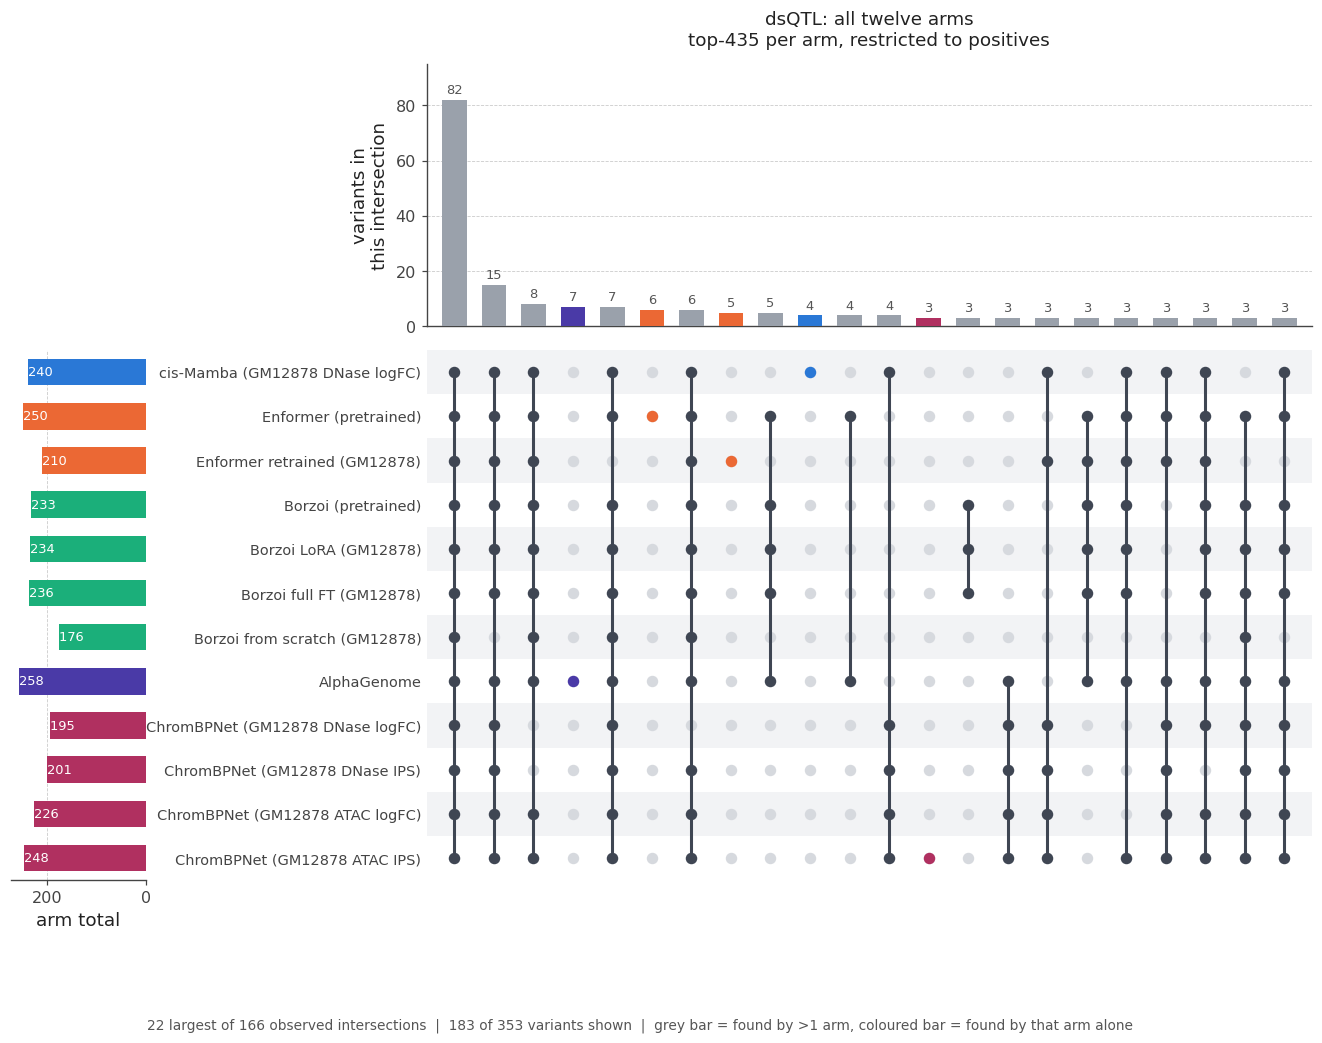

In [10]:
# All twelve arms, top 22 intersections.
Md_all = top_k_sets(DQ, K_DQ)[DQ['y'] == 1]
rows, all_rows = upset(
    Md_all, DQ['labels'], DQ['fam'],
    'dsQTL: all twelve arms',
    f'top-{K_DQ} per arm, restricted to positives',
    f'{FIGDIR}/upset_dsqtl_hits_allarms.png', max_rows=22)
plt.show()

---
## 5. The behavioural view — all called variants, truth ignored

Same sets, no restriction to positives. This says whether the arms *behave* alike. Expect more
overlap than section 3/4: two arms can agree here by both firing on the same GC-rich or
repeat-adjacent sequence, which is agreement about an artefact rather than about biology. Useful
only as a contrast with the positives-only view.


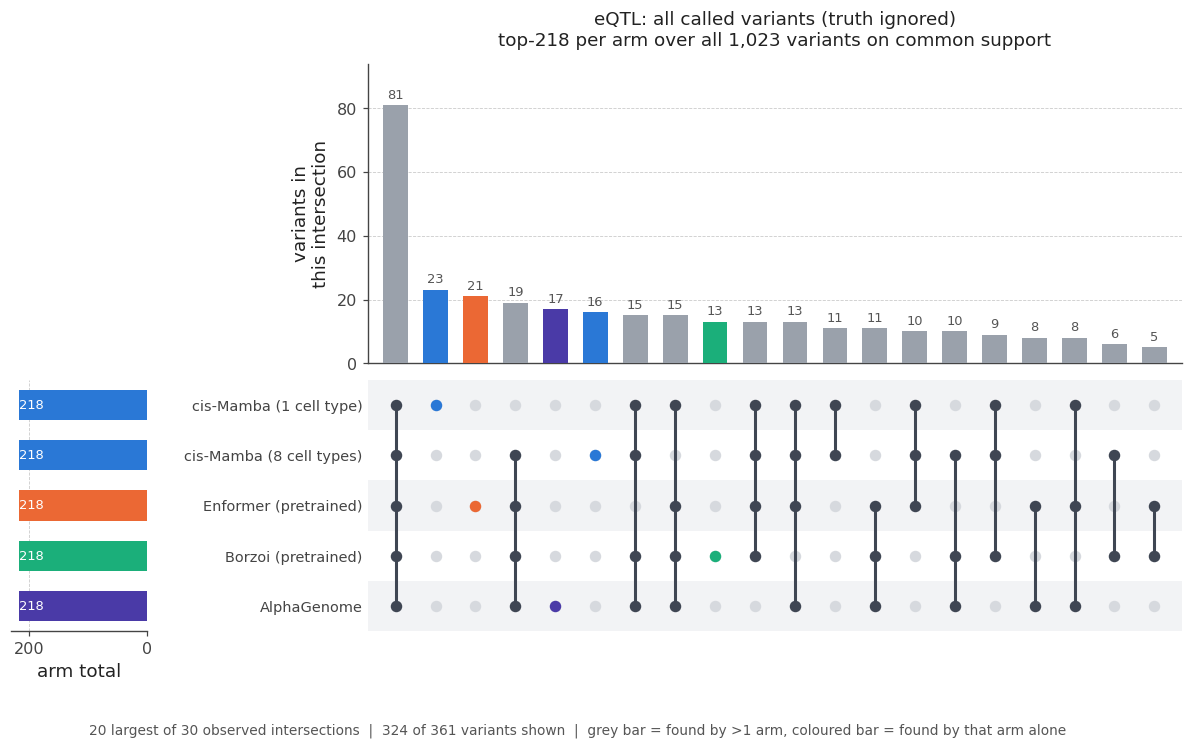

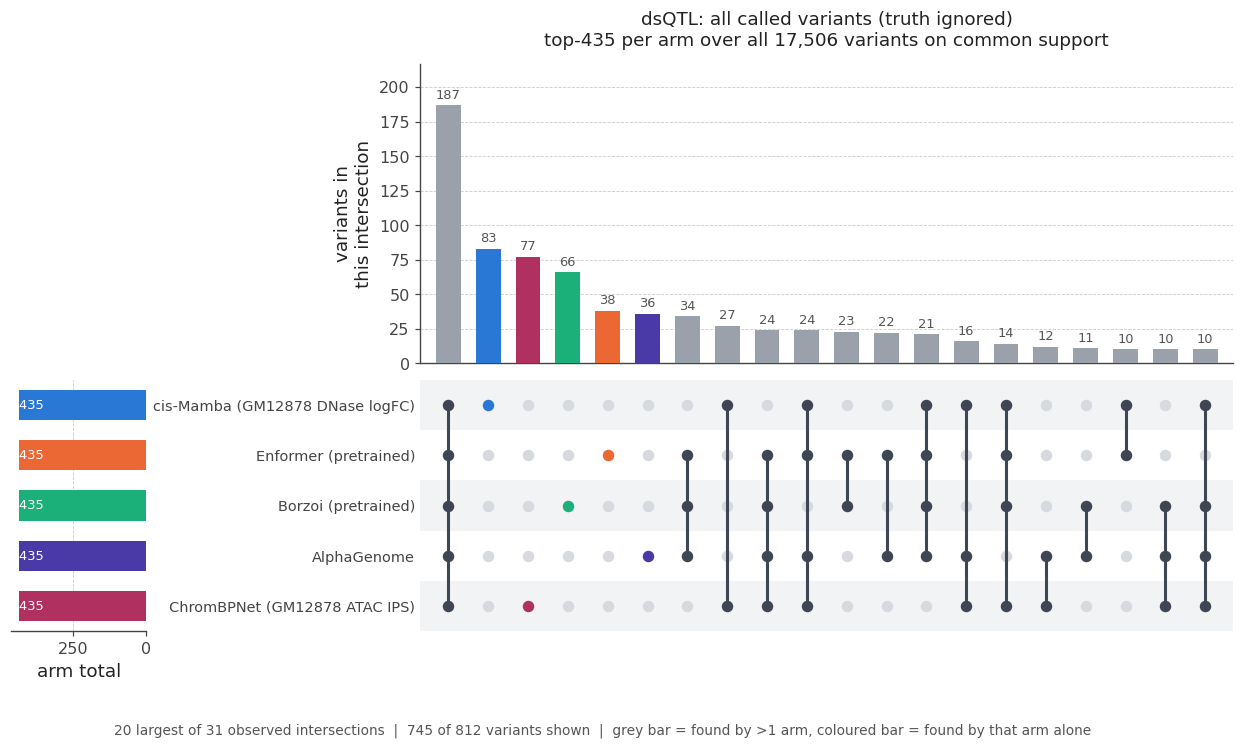

In [11]:
for B, arms, K, nm in [(EQ, ARMS_EQ, K_EQ, 'eQTL'), (DQ, ARMS_DQ, K_DQ, 'dsQTL')]:
    Mc = top_k_sets(B, K, arms)
    upset(Mc, arms, B['fam'],
          f'{nm}: all called variants (truth ignored)',
          f'top-{K} per arm over all {B["X"].shape[0]:,} variants on common support',
          f'{FIGDIR}/upset_{nm.lower()}_calls.png')
    plt.show()

---
## 6. Does the conclusion survive a different `K`?

The one check that decides whether the threshold mattered. `mean pairwise Jaccard` is how much
the arms agree; `union / best single` is how much more the union recovers than the strongest arm
alone — the ensemble headroom. If both are flat in `K`, the choice of budget was not doing the
work.


,K,recall_union,recall_best,mean_jaccard,union_over_best
0,54,0.394,0.216,0.402,1.830
1,109,0.610,0.399,0.473,1.529
2,163,0.716,0.528,0.575,1.357
3,218,0.771,0.619,0.664,1.244
4,327,0.885,0.720,0.730,1.229
5,436,0.950,0.789,0.774,1.203
6,654,0.995,0.908,0.861,1.096
7,1090,1.000,1.000,1.000,1.000


,K,recall_union,recall_best,mean_jaccard,union_over_best
0,108,0.389,0.221,0.455,1.760
1,217,0.584,0.384,0.561,1.521
2,326,0.690,0.515,0.638,1.339
3,435,0.775,0.593,0.685,1.306
4,652,0.846,0.724,0.749,1.168
5,870,0.883,0.786,0.781,1.123
6,1305,0.922,0.857,0.830,1.075
7,2175,0.966,0.901,0.878,1.071


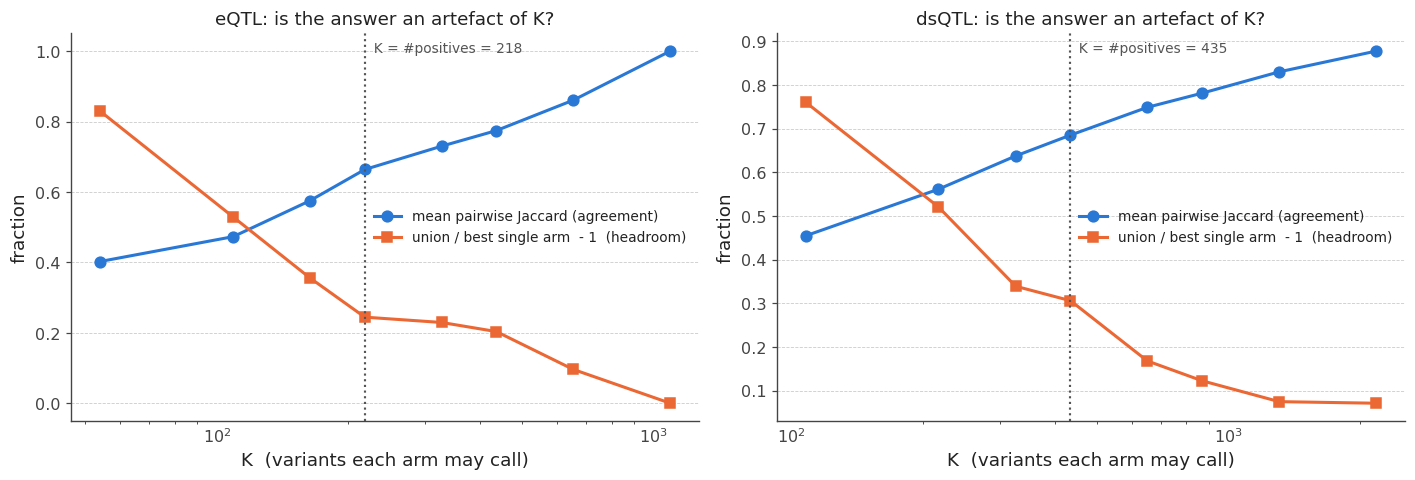

In [12]:
def k_sweep(B, arms, Ks):
    out = []
    pos = B['y'] == 1
    for K in Ks:
        M = top_k_sets(B, K, arms)
        H = M[pos]
        J = [(H[:, i] & H[:, j]).sum() / max((H[:, i] | H[:, j]).sum(), 1)
             for i in range(len(arms)) for j in range(i + 1, len(arms))]
        union, best = H.any(1).sum(), H.sum(0).max()
        out.append(dict(K=K, recall_union=union / pos.sum(), recall_best=best / pos.sum(),
                        mean_jaccard=float(np.mean(J)), union_over_best=union / max(best, 1)))
    return pd.DataFrame(out)


fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.5))
for ax, (B, arms, nm) in zip(axes, [(EQ, ARMS_EQ, 'eQTL'), (DQ, ARMS_DQ, 'dsQTL')]):
    n_pos = int(B['y'].sum())
    Ks = [int(n_pos * f) for f in (0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0)]
    sw = k_sweep(B, arms, Ks)
    display(sw.round(3))
    ax.plot(sw.K, sw.mean_jaccard, 'o-', lw=2, ms=7, color=C_OURS,
            label='mean pairwise Jaccard (agreement)')
    ax.plot(sw.K, sw.union_over_best - 1, 's-', lw=2, ms=7, color=C_ENF,
            label='union / best single arm  - 1  (headroom)')
    ax.axvline(n_pos, ls=':', lw=1.4, color=INK2)
    ax.text(n_pos, 0.98, f'  K = #positives = {n_pos}', transform=ax.get_xaxis_transform(),
            fontsize=9, color=INK2, va='top')
    ax.set_xscale('log'); ax.set_xlabel('K  (variants each arm may call)')
    ax.set_ylabel('fraction'); ax.set_title(f'{nm}: is the answer an artefact of K?', fontsize=12)
    ax.legend(fontsize=9, frameon=False); tidy(ax)
fig.tight_layout(); fig.savefig(f'{FIGDIR}/upset_k_sweep.png', bbox_inches='tight')
plt.show()

---
## 7. The numbers to quote

Per arm: how many positives it recovers, how many it recovers **alone**, and how much the union
of all arms adds over the best single arm.


In [13]:
def complementarity(B, arms, K):
    pos = B['y'] == 1
    H = top_k_sets(B, K, arms)[pos]
    n_pos = int(pos.sum())
    only = H & (H.sum(1, keepdims=True) == 1)
    rows = [dict(arm=a, family=B['fam'][a], recovered=int(H[:, i].sum()),
                 recall=H[:, i].sum() / n_pos, unique=int(only[:, i].sum()))
            for i, a in enumerate(arms)]
    df = pd.DataFrame(rows).sort_values('recovered', ascending=False).reset_index(drop=True)
    union, best = int(H.any(1).sum()), int(H.sum(0).max())
    summary = dict(positives=n_pos, best_single=best, union=union,
                   union_gain=union - best, union_recall=union / n_pos,
                   found_by_all=int((H.all(1)).sum()),
                   found_by_none=int(n_pos - H.any(1).sum()))
    return df, summary


for B, arms, K, nm in [(EQ, ARMS_EQ, K_EQ, 'eQTL'), (DQ, ARMS_DQ, K_DQ, 'dsQTL')]:
    df, s = complementarity(B, arms, K)
    print(f'===== {nm}  (K={K}) =====')
    display(df.round(3))
    print(f"  positives {s['positives']}   best single arm {s['best_single']}   "
          f"union {s['union']}  (+{s['union_gain']}, recall {s['union_recall']:.1%})")
    print(f"  found by every arm: {s['found_by_all']}    found by no arm: {s['found_by_none']}\n")

===== eQTL  (K=218) =====


,arm,family,recovered,recall,unique
0,AlphaGenome,alphagenome,135,0.619,6
1,cis-Mamba (8 cell types),ours,132,0.606,4
2,Borzoi (pretrained),borzoi,130,0.596,2
3,Enformer (pretrained),enformer,117,0.537,1
4,cis-Mamba (1 cell type),ours,112,0.514,2


  positives 218   best single arm 135   union 168  (+33, recall 77.1%)
  found by every arm: 66    found by no arm: 50

===== dsQTL  (K=435) =====


,arm,family,recovered,recall,unique
0,AlphaGenome,alphagenome,258,0.593,9
1,Enformer (pretrained),enformer,250,0.575,9
2,ChromBPNet (GM12878 ATAC IPS),chrombpnet,248,0.570,10
3,cis-Mamba (GM12878 DNase logFC),ours,240,0.552,7
4,Borzoi (pretrained),borzoi,233,0.536,11


  positives 435   best single arm 258   union 337  (+79, recall 77.5%)
  found by every arm: 151    found by no arm: 98



---
## How to read these

* **A tall left-most bar over a single dot** means that arm is finding variants nobody else
  finds — complementarity, and an argument that the arms read different signal.
* **A tall bar over a fully-connected column** means every arm agrees; those variants are the
  easy ones and they are what the AP ranking is mostly built on.
* **`union / best single`** is the honest measure of whether an ensemble is worth building. Near
  1 means the arms are redundant and the AP table already tells the whole story.
* **The positives-only view is the one to quote.** Overlap in the all-calls view can be
  agreement about a sequence artefact rather than about biology.

**Caveats.** `K` is a budget, not a significance threshold — nothing here is a calibrated call
set, and a variant "recovered" by an arm only means it ranked in that arm's top `K`. Ties at the
boundary are broken arbitrarily (the setup cell prints the largest tie-group so you can see
whether that matters). Common support differs between the two benchmarks: eQTL drops variants no
arm could see, dsQTL keeps all 17,506.
